Total functional fusion in PDO: 330
Chr entries used for plotting in PDO: 384
Total functional fusion in Tumor: 341
Chr entries used for plotting in Tumor: 460

Chromosome-wise functional fusion counts:
       PDO  Tumor
chr21    1      4
chr22    3      3
chr18    1      6
chr10    6      1
chr16    2      6
chrX     4      5
chr15    6      6
chr9    11      3
chr19    9     11
chr4    11     12
chr14   15     10
chr13    9     16
chr5     8     19
chr20    4     23
chr7     9     24
chr6    28      9
chr2    16     25
chr3    12     38
chr8    28     37
chr1    33     38
chr12   18     58
chr17   55     71
chr11   95     35
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Functional_Fusion_Chromosome_Counts_PDO_vs_Tumor.pdf
Plot saved to: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Functional_Fusion_Chromosome_Counts_PDO_vs_Tumor.png


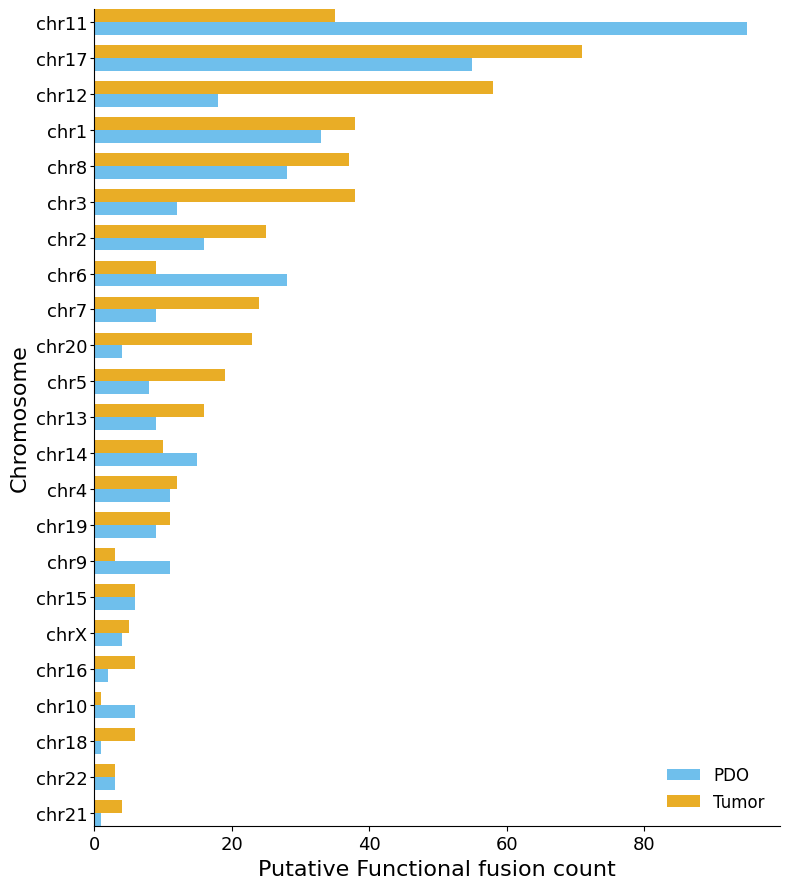

In [4]:
# Total Putative Functional Fusion Count across PDO and Tumor (based on RNA exp.)
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# FILE PATH
# ============================================================
file_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/functional_fusions_expression_only.csv"

out_pdf = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Functional_Fusion_Chromosome_Counts_PDO_vs_Tumor.pdf"
out_png = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Functional_Fusion/Functional_Fusion_Chromosome_Counts_PDO_vs_Tumor.png"

# ============================================================
# LOAD FILE
# ============================================================
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

# ============================================================
# SPLIT PDO vs TUMOR
# ============================================================
pdo_df = df[df["samples"].astype(str).str.strip().str.startswith("IPM", na=False)].copy()
tumor_df = df[df["samples"].astype(str).str.strip().str.startswith("TP", na=False)].copy()

# ============================================================
# FUNCTION: keep valid functional fusion rows
# ============================================================
def prepare_functional_fusion_df(input_df):
    temp = input_df.copy()

    # keep valid fusion rows
    temp = temp[temp["fusions"].notna()]
    temp = temp[~temp["fusions"].astype(str).str.strip().isin(["", "not_applicable", "-"])]

    # keep valid chromosome columns
    temp = temp[temp["chrA"].notna() & temp["chrB"].notna()].copy()
    temp["chrA"] = temp["chrA"].astype(str).str.strip()
    temp["chrB"] = temp["chrB"].astype(str).str.strip()

    temp = temp[
        ~temp["chrA"].isin(["", "nan"]) &
        ~temp["chrB"].isin(["", "nan"])
    ].copy()

    temp["fusions"] = temp["fusions"].astype(str).str.strip()
    temp = temp[temp["fusions"] != ""].copy()

    return temp

# ============================================================
# FUNCTION: create chromosome entries for plotting
# One fusion contributes once per unique chromosome involved
# ============================================================
def make_chr_entry_df(input_df):
    rows = []

    for _, row in input_df.iterrows():
        chroms = sorted(set([row["chrA"], row["chrB"]]))
        for chrom in chroms:
            rows.append({
                "samples": row["samples"],
                "fusions": row["fusions"],
                "Chr": chrom
            })

    return pd.DataFrame(rows)

# ============================================================
# RAW TOTAL FUNCTIONAL FUSION COUNT
# ============================================================
pdo_raw_total = (
    pdo_df["fusions"]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda x: ~x.isin(["", "not_applicable", "-"])]
    .shape[0]
)

tumor_raw_total = (
    tumor_df["fusions"]
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda x: ~x.isin(["", "not_applicable", "-"])]
    .shape[0]
)

# ============================================================
# PREPARE DATA FOR PLOTTING
# ============================================================
pdo_valid_df = prepare_functional_fusion_df(pdo_df)
tumor_valid_df = prepare_functional_fusion_df(tumor_df)

pdo_chr_df = make_chr_entry_df(pdo_valid_df)
tumor_chr_df = make_chr_entry_df(tumor_valid_df)

print(f"Total functional fusion in PDO: {pdo_raw_total}")
print(f"Chr entries used for plotting in PDO: {len(pdo_chr_df)}")

print(f"Total functional fusion in Tumor: {tumor_raw_total}")
print(f"Chr entries used for plotting in Tumor: {len(tumor_chr_df)}")

# ============================================================
# COUNT FUSIONS PER CHROMOSOME
# ============================================================
pdo_counts = pdo_chr_df["Chr"].value_counts()
tumor_counts = tumor_chr_df["Chr"].value_counts()

count_df = pd.concat(
    [pdo_counts.rename("PDO"), tumor_counts.rename("Tumor")],
    axis=1
).fillna(0)

count_df = count_df.astype(int)
count_df["Total"] = count_df["PDO"] + count_df["Tumor"]
count_df = count_df.sort_values("Total").drop(columns="Total")

print("\nChromosome-wise functional fusion counts:")
print(count_df)

# ============================================================
# PLOT SETTINGS
# ============================================================
bar_height = 0.34
group_gap = 0.95
y_pos = np.arange(len(count_df)) * group_gap

fig, ax = plt.subplots(figsize=(8, 9))

# PDO bar
ax.barh(
    y_pos - bar_height / 2,
    count_df["PDO"],
    height=bar_height,
    color="#56B4E9",
    alpha=0.85,
    label="PDO"
)

# Tumor bar
ax.barh(
    y_pos + bar_height / 2,
    count_df["Tumor"],
    height=bar_height,
    color="#E69F00",
    alpha=0.85,
    label="Tumor"
)

# Y-axis labels
ax.set_yticks(y_pos)
ax.set_yticklabels(count_df.index)

ax.set_xlabel("Putative Functional fusion count", fontsize=16)
ax.set_ylabel("Chromosome", fontsize=16)

ax.tick_params(axis='y', pad=2, labelsize=13, length=3)
ax.tick_params(axis='x', labelsize=13)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylim(y_pos[0] - bar_height, y_pos[-1] + bar_height)

ax.legend(frameon=False, fontsize=12)

plt.tight_layout()

plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.savefig(out_png, dpi=300, bbox_inches="tight")

print(f"Plot saved to: {out_pdf}")
print(f"Plot saved to: {out_png}")

plt.show()